# Khám Phá Dữ Liệu Khảo Sát Định Hướng Nghề Nghiệp (EDA)

Notebook này thực hiện khám phá và kiểm tra chất lượng dữ liệu gốc tại `data/raw/survey.csv`, bao gồm:
1. **Tổng quan dữ liệu & Kiểm tra Schema** (kích thước, kiểu dữ liệu, giá trị khuyết).
2. **Kiểm tra độ lệch nhãn** (phân bố các nhóm nghề `N1`, `N2`, `N3`, `N4` và nghề cụ thể).
3. **Kiểm tra phân bố điểm Likert (1–5)** của **8 kỹ năng mềm** và **6 nhóm sở thích RIASEC**.
4. **Thống kê các giá trị chuỗi** ở 2 cột phân loại **`Đối tượng công việc`** và **`Môi trường`**.

In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm thư mục gốc vào sys.path để import từ src
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import RAW_SURVEY_PATH
from src.schema import (
    SKILL_FEATURES,
    RIASEC_FEATURES,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    REFERENCE_COLUMNS,
    VALID_LIKERT_VALUES,
     validate_dataframe,
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

## 1. Đọc Dữ Liệu & Kiểm TraTính Hợp Lệ Theo Schema

In [4]:
df = pd.read_csv(RAW_SURVEY_PATH, encoding="utf-8")
schema_errors = validate_dataframe(df, require_target=True, require_reference=True)

print(f"Đường dẫn dữ liệu: {RAW_SURVEY_PATH.relative_to(PROJECT_ROOT)}")
print(f"Kích thước bộ dữ liệu: {df.shape[0]} dòng x {df.shape[1]} cột")
print(f"Số giá trị bị khuyết (NaN): {df.isnull().sum().sum()}")
print(f"Kết quả kiểm tra Schema: {'Hợp lệ (0 lỗi)' if not schema_errors else schema_errors}")

df.head()

Đường dẫn dữ liệu: data\raw\survey.csv
Kích thước bộ dữ liệu: 190 dòng x 19 cột
Số giá trị bị khuyết (NaN): 0
Kết quả kiểm tra Schema: Hợp lệ (0 lỗi)


,Khả năng tư duy logic,Năng lực tính toán và phân tích số liệu,Công nghệ,Sáng tạo,Giao tiếp,Tổ chức,Cẩn thận,Đồng cảm,RIASEC_R_Thuc_hanh,RIASEC_I_Nghien_cuu,RIASEC_A_Nghe_thuat,RIASEC_S_Xa_hoi,RIASEC_E_Thuyet_phuc,RIASEC_C_Quy_cu,Đối tượng công việc,Môi trường,Nghề cụ thể,Nhóm nghề,Tên nhóm nghề
0,4,4,5,4,3,2,4,3,3,4,2,3,2,2,Phần mềm,Linh hoạt - sáng tạo,Lập trình viên,N1,Công nghệ - Kỹ thuật - Phân tích
1,5,4,4,5,3,2,4,3,3,5,3,2,2,4,Phần mềm,Có quy trình,Lập trình viên,N1,Công nghệ - Kỹ thuật - Phân tích
2,5,4,4,4,4,4,4,3,3,4,2,3,2,3,Phần mềm,Tương tác - hợp tác,Lập trình viên,N1,Công nghệ - Kỹ thuật - Phân tích
3,5,4,5,5,3,3,3,2,2,5,3,2,1,3,Phần mềm,Linh hoạt - sáng tạo,Lập trình viên,N1,Công nghệ - Kỹ thuật - Phân tích
4,4,2,4,5,3,2,4,3,2,5,2,1,3,3,Phần mềm,Có quy trình,Lập trình viên,N1,Công nghệ - Kỹ thuật - Phân tích


## 2. Kiểm Tra Độ Lệch Nhãn (Phân Bố N1, N2, N3, N4)

Đánh giá số lượng mẫu và tỷ lệ phần trăm của 4 nhãn mục tiêu `Nhóm nghề` (`N1`, `N2`, `N3`, `N4`) cùng các nhãn tham chiếu `Tên nhóm nghề` và `Nghề cụ thể`.

In [5]:
label_counts = (
    df.groupby(["Nhóm nghề", "Tên nhóm nghề"])
    .size()
    .reset_index(name="Số lượng mẫu")
)
label_counts["Tỷ lệ (%)"] = (label_counts["Số lượng mẫu"] / len(df) * 100).round(2)

max_count = label_counts["Số lượng mẫu"].max()
min_count = label_counts["Số lượng mẫu"].min()
imbalance_ratio = max_count / min_count

print("=== PHÂN BỐ NHÃN MỤC TIÊU (NHÓM NGHỀ) ===")
print(label_counts.to_string(index=False))
print(f"\nTỷ lệ lệch nhãn (Max / Min): {imbalance_ratio:.2f} ({max_count} / {min_count}) -> Bộ dữ liệu tương đối cân bằng.")

=== PHÂN BỐ NHÃN MỤC TIÊU (NHÓM NGHỀ) ===
Nhóm nghề                        Tên nhóm nghề  Số lượng mẫu  Tỷ lệ (%)
       N1     Công nghệ - Kỹ thuật - Phân tích            50      26.32
       N2     Kinh doanh - Tài chính - Quản lý            50      26.32
       N3   Sáng tạo - Truyền thông - Thiết kế            40      21.05
       N4 Giáo dục – Xã hội – Hỗ trợ con người            50      26.32

Tỷ lệ lệch nhãn (Max / Min): 1.25 (50 / 40) -> Bộ dữ liệu tương đối cân bằng.


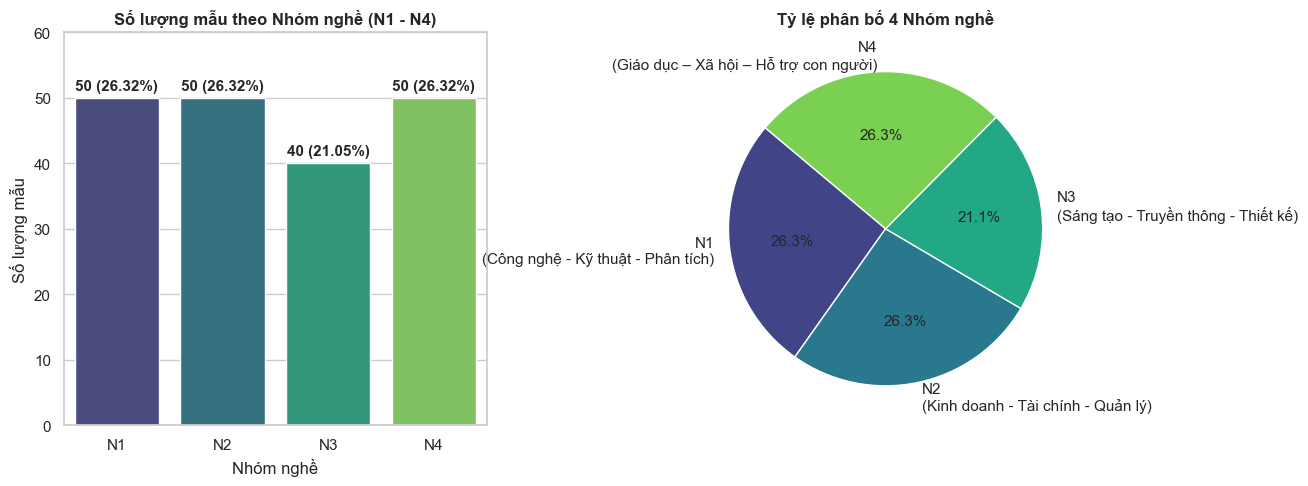

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ cột số lượng mẫu
sns.barplot(
    data=label_counts,
    x="Nhóm nghề",
    y="Số lượng mẫu",
    hue="Nhóm nghề",
    palette="viridis",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Số lượng mẫu theo Nhóm nghề (N1 - N4)", fontweight="bold")
axes[0].set_ylim(0, 60)
for idx, row in label_counts.iterrows():
    axes[0].text(
        idx,
        row["Số lượng mẫu"] + 1.2,
        f"{row['Số lượng mẫu']} ({row['Tỷ lệ (%)']}%)",
        ha="center",
        fontweight="bold",
    )

# Biểu đồ tròn tỷ lệ phần trăm
axes[1].pie(
    label_counts["Số lượng mẫu"],
    labels=[f"{r['Nhóm nghề']}\n({r['Tên nhóm nghề']})" for _, r in label_counts.iterrows()],
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("viridis", 4),
)
axes[1].set_title("Tỷ lệ phân bố 4 Nhóm nghề", fontweight="bold")

plt.tight_layout()
plt.show()

In [5]:
career_dist = (
    df.groupby(["Nhóm nghề", "Nghề cụ thể"])
    .size()
    .reset_index(name="Số lượng")
    .sort_values(["Nhóm nghề", "Số lượng"], ascending=[True, False])
)
print("=== PHÂN BỐ NGHỀ CỤ THỂ THEO NHÓM NGHỀ ===")
print(career_dist.to_string(index=False))

=== PHÂN BỐ NGHỀ CỤ THỂ THEO NHÓM NGHỀ ===
Nhóm nghề  Nghề cụ thể                      Số lượng
N1         Lập trình viên                         10
N1         Chuyên viên phân tích dữ liệu           8
N1         Kiểm thử phần mềm                       8
N1         Kỹ sư cơ khí                            8
N1         Kỹ sư tự động hóa                       8
N1         Kỹ sư điện                              8
N2         Chuyên viên kinh doanh                 10
N2         Chuyên viên logistics                  10
N2         Chuyên viên phân tích tài chính        10
N2         Chuyên viên vận hành                   10
N2         Kế toán viên                           10
N3         Digital Marketing                       8
N3         Dựng phim - Biên tập video              8
N3         Sáng tạo nội dung                       8
N3         Thiết kế UI/UX                          8
N3         Thiết kế đồ họa                         8
N4         Công tác xã hội                        10
N4 

## 3. Kiểm Tra Phân Bố Điểm 1–5 Của 8 Kỹ Năng Mềm Và 6 Nhóm RIASEC

- **8 Kỹ năng mềm**: thang đo `1 (Rất thấp)` $\rightarrow$ `5 (Giỏi)`.
- **6 Nhóm sở thích RIASEC**: thang đo `1 (Rất không thích)` $\rightarrow$ `5 (Rất thích)`.

In [7]:
# Thống kê tần suất điểm 1 - 5 cho 8 Kỹ năng mềm
skill_freq = pd.DataFrame(index=SKILL_FEATURES)
for score in VALID_LIKERT_VALUES:
    skill_freq[f"Điểm {score}"] = [(df[col] == score).sum() for col in SKILL_FEATURES]

skill_freq["Trung bình"] = df[SKILL_FEATURES].mean().round(2)
skill_freq["Độ lệch chuẩn"] = df[SKILL_FEATURES].std().round(2)

print("=== BẢNG TẦN SUẤT ĐIỂM 1-5 CỦA 8 KỸ NĂNG MỀM ===")
print(skill_freq.to_string())

=== BẢNG TẦN SUẤT ĐIỂM 1-5 CỦA 8 KỸ NĂNG MỀM ===
                                         Điểm 1  Điểm 2  Điểm 3  Điểm 4  Điểm 5  Trung bình  Độ lệch chuẩn
Khả năng tư duy logic                         0      20      73      61      36        3.59           0.91
Năng lực tính toán và phân tích số liệu      17      57      54      33      29        3.00           1.20
Công nghệ                                     0      29      73      68      20        3.42           0.87
Sáng tạo                                     21      31      49      43      46        3.33           1.30
Giao tiếp                                     8      17      49      55      61        3.76           1.12
Tổ chức                                       0       4      56      88      42        3.88           0.77
Cẩn thận                                      0       2      28      89      71        4.21           0.72
Đồng cảm                                     11      25      73      40      41        3.39    

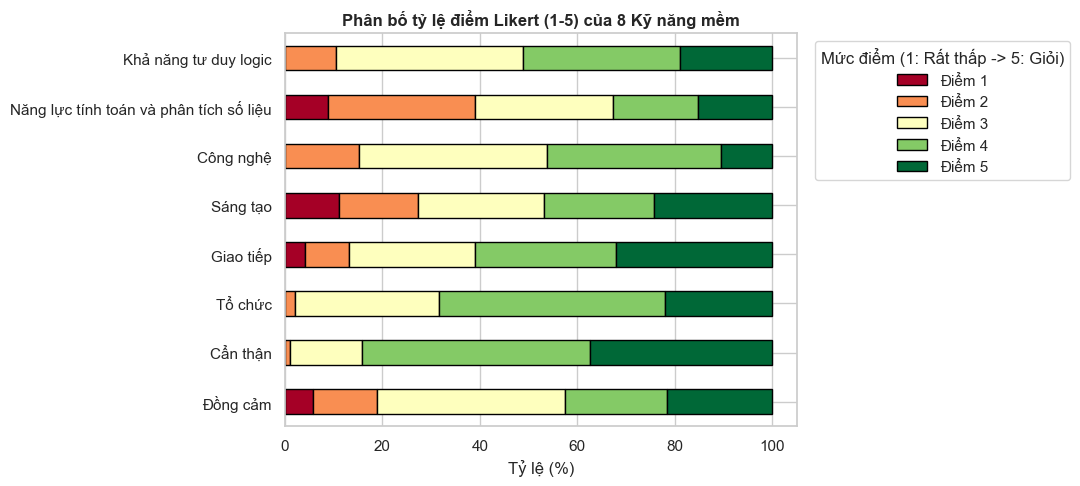

In [8]:
# Biểu đồ phân bố điểm 1-5 của 8 Kỹ năng mềm
skill_pct = skill_freq[[f"Điểm {s}" for s in VALID_LIKERT_VALUES]].div(len(df)) * 100
ax = skill_pct.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 5),
    colormap="RdYlGn",
    edgecolor="black",
)
plt.title("Phân bố tỷ lệ điểm Likert (1-5) của 8 Kỹ năng mềm", fontweight="bold")
plt.xlabel("Tỷ lệ (%)")
plt.legend(title="Mức điểm (1: Rất thấp -> 5: Giỏi)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [10]:
# Thống kê tần suất điểm 1 - 5 cho 6 nhóm RIASEC
riasec_freq = pd.DataFrame(index=RIASEC_FEATURES)
for score in VALID_LIKERT_VALUES:
    riasec_freq[f"Điểm {score}"] = [(df[col] == score).sum() for col in RIASEC_FEATURES]

riasec_freq["Trung bình"] = df[RIASEC_FEATURES].mean().round(2)
riasec_freq["Độ lệch chuẩn"] = df[RIASEC_FEATURES].std().round(2)

print("=== BẢNG TẦN SUẤT ĐIỂM 1-5 CỦA 6 NHÓM SỞ THÍCH RIASEC ===")
print(riasec_freq.to_string())

=== BẢNG TẦN SUẤT ĐIỂM 1-5 CỦA 6 NHÓM SỞ THÍCH RIASEC ===
                      Điểm 1  Điểm 2  Điểm 3  Điểm 4  Điểm 5  Trung bình  Độ lệch chuẩn
RIASEC_R_Thuc_hanh        49      59      39      22      21        2.51           1.29
RIASEC_I_Nghien_cuu        0      29      69      50      42        3.55           1.00
RIASEC_A_Nghe_thuat       23      59      51      20      37        2.94           1.30
RIASEC_S_Xa_hoi           10      46      55      36      43        3.29           1.21
RIASEC_E_Thuyet_phuc      19      29      68      42      32        3.21           1.19
RIASEC_C_Quy_cu            0      15      62      70      43        3.74           0.90


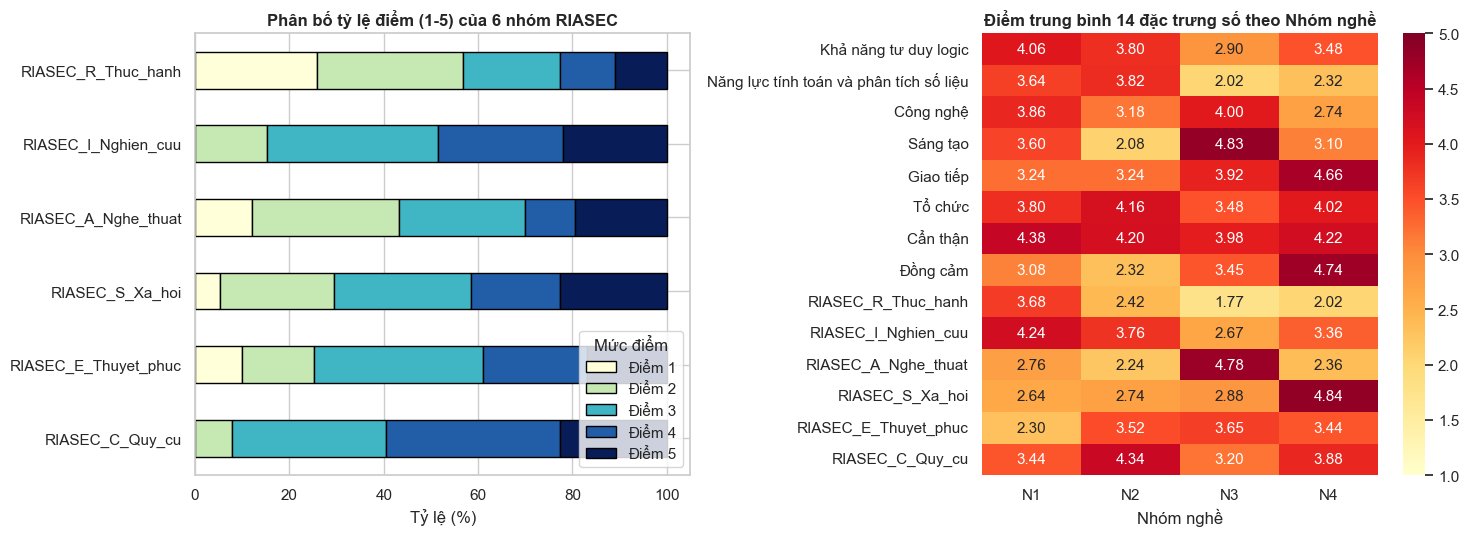

In [11]:
# Biểu đồ phân bố điểm 1-5 của 6 nhóm RIASEC và Heatmap trung bình theo Nhóm nghề
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

riasec_pct = riasec_freq[[f"Điểm {s}" for s in VALID_LIKERT_VALUES]].div(len(df)) * 100
riasec_pct.plot(
    kind="barh",
    stacked=True,
    colormap="YlGnBu",
    edgecolor="black",
    ax=axes[0],
)
axes[0].set_title("Phân bố tỷ lệ điểm (1-5) của 6 nhóm RIASEC", fontweight="bold")
axes[0].set_xlabel("Tỷ lệ (%)")
axes[0].invert_yaxis()
axes[0].legend(title="Mức điểm", loc="lower right")

# Heatmap điểm trung bình của 14 đặc trưng số theo 4 Nhóm nghề
group_means = df.groupby("Nhóm nghề")[NUMERIC_FEATURES].mean().T
sns.heatmap(
    group_means,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=1,
    vmax=5,
    ax=axes[1],
)
axes[1].set_title("Điểm trung bình 14 đặc trưng số theo Nhóm nghề", fontweight="bold")

plt.tight_layout()
plt.show()

## 4. Thống Kê Các Giá Trị Chuỗi Ở Cột `Đối tượng công việc` Và `Môi trường`

Kiểm tra danh sách các danh mục chuỗi duy nhất, tần suất xuất hiện và sự phân bố của chúng theo từng nhóm nghề `N1`, `N2`, `N3`, `N4`.

In [12]:
work_obj_stats = (
    df.groupby("Đối tượng công việc")
    .agg(
        Số_lượng=("Nhóm nghề", "count"),
        Nhóm_nghề=("Nhóm nghề", lambda s: ", ".join(sorted(s.unique()))),
    )
    .reset_index()
    .sort_values(["Số_lượng", "Đối tượng công việc"], ascending=[False, True])
)
work_obj_stats["Tỷ lệ (%)"] = (work_obj_stats["Số_lượng"] / len(df) * 100).round(2)
work_obj_stats = work_obj_stats[["Đối tượng công việc", "Số_lượng", "Tỷ lệ (%)", "Nhóm_nghề"]]
work_obj_stats.columns = ["Đối tượng công việc", "Số lượng", "Tỷ lệ (%)", "Nhóm nghề tương ứng"]

print(f"=== THỐNG KÊ CỘT 'Đối tượng công việc' ({work_obj_stats.shape[0]} giá trị duy nhất) ===")
print(work_obj_stats.to_string(index=False))

=== THỐNG KÊ CỘT 'Đối tượng công việc' (19 giá trị duy nhất) ===
      Đối tượng công việc  Số lượng  Tỷ lệ (%) Nhóm nghề tương ứng
       Máy móc - thiết bị        24      12.63                  N1
                 Phần mềm        18       9.47                  N1
         Bệnh nhân - y tế        10       5.26                  N4
Chuỗi cung ứng - hàng hóa        10       5.26                  N2
      Cộng đồng - yếu thế        10       5.26                  N4
  Khách hàng - thị trường        10       5.26                  N2
        Nhân sự - tổ chức        10       5.26                  N4
    Quy trình - hoạt động        10       5.26                  N2
       Sổ sách - chứng từ        10       5.26                  N2
      Tài chính - số liệu        10       5.26                  N2
         Tâm lý - hành vi        10       5.26                  N4
                  Dữ liệu         8       4.21                  N1
       Hình ảnh - Ấn phẩm         8       4.21                  

In [13]:
env_stats = (
    df["Môi trường"]
    .value_counts()
    .rename_axis("Môi trường")
    .reset_index(name="Số lượng")
)
env_stats["Tỷ lệ (%)"] = (env_stats["Số lượng"] / len(df) * 100).round(2)

print(f"=== THỐNG KÊ CỘT 'Môi trường' ({env_stats.shape[0]} giá trị duy nhất) ===")
print(env_stats.to_string(index=False))

print("\n=== BẢNG CHÉO (CROSSTAB): MÔI TRƯỜNG x NHÓM NGHỀ ===")
env_crosstab = pd.crosstab(df["Môi trường"], df["Nhóm nghề"], margins=True)
print(env_crosstab)

=== THỐNG KÊ CỘT 'Môi trường' (6 giá trị duy nhất) ===
           Môi trường  Số lượng  Tỷ lệ (%)
         Có quy trình        57      30.00
  Tương tác - hợp tác        55      28.95
 Linh hoạt - sáng tạo        50      26.32
Cạnh tranh - mục tiêu        11       5.79
 Phân tích chuyên sâu         9       4.74
    Ổn định - rõ ràng         8       4.21

=== BẢNG CHÉO (CROSSTAB): MÔI TRƯỜNG x NHÓM NGHỀ ===
Nhóm nghề              N1  N2  N3  N4  All
Môi trường                                
Có quy trình           18  16   8  15   57
Cạnh tranh - mục tiêu   0   3   7   1   11
Linh hoạt - sáng tạo   17   9  15   9   50
Phân tích chuyên sâu    0   6   0   3    9
Tương tác - hợp tác    15  13  10  17   55
Ổn định - rõ ràng       0   3   0   5    8
All                    50  50  40  50  190


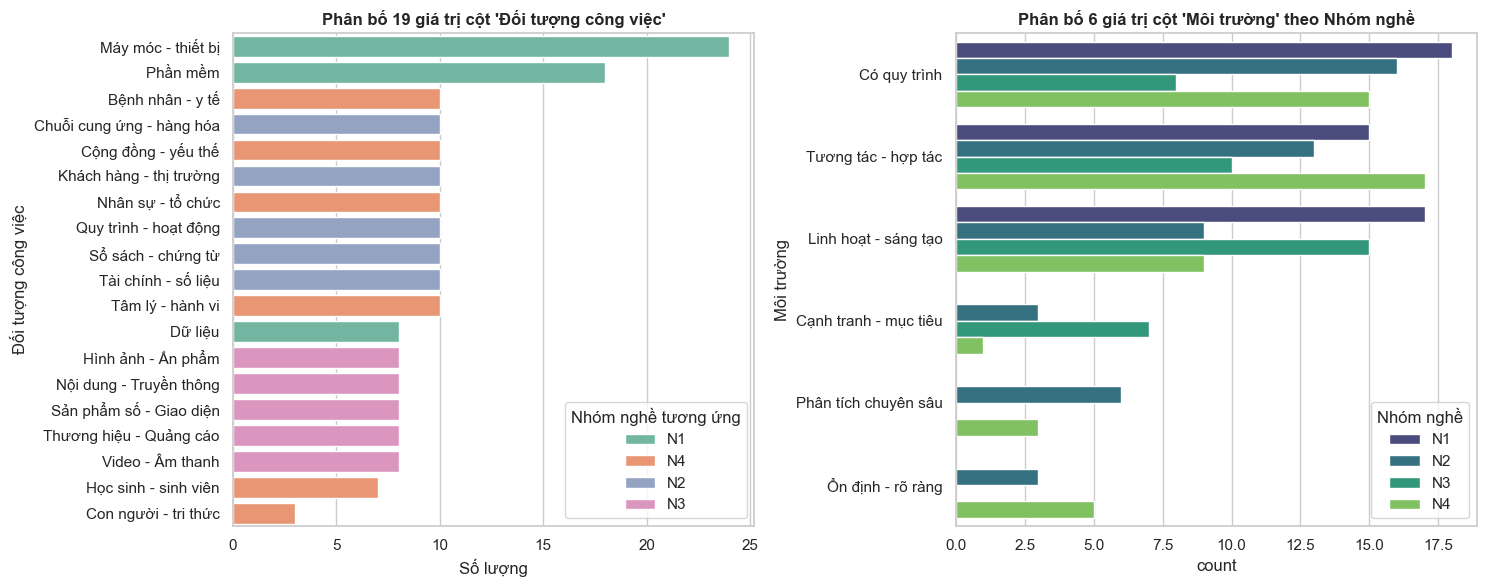

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=work_obj_stats,
    y="Đối tượng công việc",
    x="Số lượng",
    hue="Nhóm nghề tương ứng",
    dodge=False,
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Phân bố 19 giá trị cột 'Đối tượng công việc'", fontweight="bold")

sns.countplot(
    data=df,
    y="Môi trường",
    hue="Nhóm nghề",
    order=env_stats["Môi trường"],
    palette="viridis",
    ax=axes[1],
)
axes[1].set_title("Phân bố 6 giá trị cột 'Môi trường' theo Nhóm nghề", fontweight="bold")

plt.tight_layout()
plt.show()